## Assignment: Image recognition
- Alumno 1: Alex Sierra Alcalá
- Alumno 2: Roberto Inclán Alfonso
- Alumno 3: Mario Hernández Trillo

The goals of the assignment are:
* Develop proficiency in using Tensorflow/Keras for training Neural Nets (NNs).
* Put into practice the acquired knowledge to optimize the parameters and architecture of a feedforward Neural Net (ffNN), in the context of an image recognition problem.
* Put into practice NNs specially conceived for analysing images. Design and optimize the parameters of a Convolutional Neural Net (CNN) to deal with previous task.
* Train popular architectures from scratch (e.g., GoogLeNet, VGG, ResNet, ...), and compare the results with the ones provided by their pre-trained versions using transfer learning.

Follow the link below to download the classification data set  “xview_recognition”: [https://drive.upm.es/s/2DDPE2zHw5dbM3G](https://drive.upm.es/s/2DDPE2zHw5dbM3G)

In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

import keras
# Reproducibility: same seed -> same run, also on GPU (EXP-001)
keras.utils.set_random_seed(1)
tf.config.experimental.enable_op_determinism()

I0000 00:00:1791036299.375034  483950 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791036299.645446  483950 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791036301.413799  483950 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import uuid
import numpy as np

class GenericObject:
    """
    Generic object data.
    """
    def __init__(self):
        self.id = uuid.uuid4()
        self.bb = (-1, -1, -1, -1)
        self.category= -1
        self.score = -1

class GenericImage:
    """
    Generic image data.
    """
    def __init__(self, filename):
        self.filename = filename
        self.tile = np.array([-1, -1, -1, -1])  # (pt_x, pt_y, pt_x+width, pt_y+height)
        self.objects = list([])

    def add_object(self, obj: GenericObject):
        self.objects.append(obj)

In [3]:
categories = {0: 'Cargo plane', 1: 'Small car', 2: 'Bus', 3: 'Truck', 4: 'Motorboat', 5: 'Fishing vessel', 6: 'Dump truck', 7: 'Excavator', 8: 'Building', 9: 'Helipad', 10: 'Storage tank', 11: 'Shipping container', 12: 'Pylon'}

In [4]:
import warnings
import rasterio
import numpy as np

def load_geoimage(filename):
    warnings.filterwarnings('ignore', category=rasterio.errors.NotGeoreferencedWarning)
    src_raster = rasterio.open('./xview_recognition/'+filename, 'r')
    # RasterIO to OpenCV (see inconsistencies between libjpeg and libjpeg-turbo)
    input_type = src_raster.profile['dtype']
    input_channels = src_raster.count
    img = np.zeros((src_raster.height, src_raster.width, src_raster.count), dtype=input_type)
    for band in range(input_channels):
        img[:, :, band] = src_raster.read(band+1)
    return img

#### Training
Design and train a ffNN to deal with the “xview_recognition” classification task.

In [5]:
import json

# Load database
json_file = './xview_recognition/xview_ann_train.json'
with open(json_file) as ifs:
    json_data = json.load(ifs)
ifs.close()

In [6]:
import numpy as np

counts = dict.fromkeys(categories.values(), 0)
anns = []
for json_img, json_ann in zip(json_data['images'].values(), json_data['annotations'].values()):
    image = GenericImage(json_img['filename'])
    image.tile = np.array([0, 0, json_img['width'], json_img['height']])
    obj = GenericObject()
    obj.bb = (int(json_ann['bbox'][0]), int(json_ann['bbox'][1]), int(json_ann['bbox'][2]), int(json_ann['bbox'][3]))
    obj.category = json_ann['category_id']
    counts[obj.category] += 1
    image.add_object(obj)
    anns.append(image)
print(counts)

{'Cargo plane': 635, 'Small car': 3324, 'Bus': 1768, 'Truck': 2210, 'Motorboat': 1069, 'Fishing vessel': 706, 'Dump truck': 1236, 'Excavator': 789, 'Building': 3594, 'Helipad': 111, 'Storage tank': 1469, 'Shipping container': 1523, 'Pylon': 312}


**Split.** Stratified by class with a fixed seed, so that the small classes (Helipad: 111 images) keep exactly
their 10 % in validation and runs are comparable (EXP-001).

In [7]:
from sklearn.model_selection import train_test_split

# Stratified split: every class keeps its 10 % in validation (EXP-001)
labels = np.array([list(categories.values()).index(ann.objects[0].category) for ann in anns])
idx_train, idx_valid = train_test_split(np.arange(len(anns)), test_size=0.1, random_state=1, shuffle=True, stratify=labels)
anns_train, anns_valid = [anns[i] for i in idx_train], [anns[i] for i in idx_valid]
print('Number of training images: ' + str(len(anns_train)))
print('Number of validation images: ' + str(len(anns_valid)))

Number of training images: 16871
Number of validation images: 1875


In [8]:
from xview_data import load_cache

# Image cache (CHG-007): every TIF is read once with load_geoimage, downsampled by area averaging to RES x RES and
# kept as uint8 in cache/train_<RES>.npy; the order is the one of the annotations file (= the order of `anns`).
RES = 16
x_all = load_cache('train', RES)
y_all = labels
print(x_all.shape, x_all.dtype)

(18746, 16, 16, 3) uint8


**Model.** `Input(16×16×3) → Rescaling(1/255) → Flatten → 4 × [Dense(256) → LeakyReLU(0.3)] → Dense(13, softmax)`.
- Pixels are scaled to [0, 1] inside the model (EXP-002): with raw values in [0, 255] the logits were huge and the softmax
  saturated (loss ≈ 3 000). Being part of the model, training, validation and test get the same preprocessing.
- Images are downsampled to 16×16 (area averaging) when cached (EXP-005): at 224×224 the first layer had 38.5 M weights
  per 256 units and most ReLU units died; the small input trains better and faster.
- Hidden layers: 4 × [Dense(256) → LeakyReLU(0.3)] with He initialisation (EXP-006, EXP-007). Depth beat width at the
  same parameter budget, and LeakyReLU removed the dead ReLU units. The original `Activation('relu')` right after
  `Flatten` was the identity on non-negative pixels and is gone.

In [9]:
# Load architecture
from keras import Input, Model
from keras.layers import Dense, Flatten, Rescaling, LeakyReLU

print('Load model')
inputs = Input(shape=(16, 16, 3))
x = Rescaling(1.0 / 255)(inputs)
x = Flatten()(x)
for _ in range(4):
    x = Dense(256, kernel_initializer='he_normal')(x)
    x = LeakyReLU(negative_slope=0.3)(x)
outputs = Dense(len(categories), activation='softmax')(x)
model = Model(inputs, outputs)
model.summary()

Load model


I0000 00:00:1791036306.669855  483950 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 16, 16, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 16, 16, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 13)             │         3,341 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 397,581 (1.52 MB)

 Trainable params: 397,581 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
from keras.optimizers import Adam

# Adam with AMSGrad and clipnorm as in the original; beta_1 = 0.95 and lr = 1.2e-3 (square-root rule for batch 256)
# chosen in phase 5 (EXP-009, EXP-010)
opt = Adam(learning_rate=0.0012, beta_1=0.95, beta_2=0.999, epsilon=1e-8, amsgrad=True, clipnorm=1.0)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

In [11]:
import os
import json
from datetime import datetime

# Experiment tracking: EXP_ID must match the entry in LOGBOOK.md (one folder per run in experiments/runs/)
EXP_ID = 'EXP-010'
run_id = EXP_ID + '_' + datetime.now().strftime('%Y%m%d-%H%M%S')
run_dir = os.path.join('experiments', 'runs', run_id)
os.makedirs(run_dir, exist_ok=True)
with open(os.path.join(run_dir, 'model_summary.txt'), 'w', encoding='utf-8') as ofs:
    model.summary(print_fn=lambda line, *args, **kwargs: ofs.write(line + '\n'))
optimizer_config = model.optimizer.get_config()
print('Run: ' + run_id)

Run: EXP-010_20261003-160510


**Callbacks.** In the original, EarlyStopping (patience 40) could never fire in 20 epochs and ReduceLROnPlateau
(patience 10) at most once; both watched the noisy `val_accuracy`. They now watch the validation mean recall, the
metric that matters with imbalanced classes, with patiences adapted to the run length.

In [12]:
from keras.callbacks import TerminateOnNaN, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from experiment_utils import EpochMetrics

# Callbacks adapted to the run length and monitoring the validation mean recall (EXP-003).
# EpochMetrics computes val_loss, val_accuracy and val_mean_recall in one batched pass and must go first.
epoch_metrics = EpochMetrics(x_all, y_all, idx_valid)
model_checkpoint = ModelCheckpoint('model.keras', monitor='val_mean_recall', mode='max', verbose=1, save_best_only=True)
reduce_lr = ReduceLROnPlateau('val_mean_recall', mode='max', factor=0.1, patience=4, verbose=1)
early_stop = EarlyStopping('val_mean_recall', mode='max', patience=10, verbose=1)
terminate = TerminateOnNaN()
csv_logger = CSVLogger(os.path.join(run_dir, 'history.csv'))
callbacks = [epoch_metrics, model_checkpoint, reduce_lr, early_stop, terminate, csv_logger]

**Training changes.** Batches come from the cache instead of re-reading the TIFs every epoch, in batches of 256
(15× faster epochs than batch 16 with the same validation result within seed noise: EXP-010). EarlyStopping and
ReduceLROnPlateau monitor the validation mean recall with patiences that fit the run length (10 and 4 epochs, up to 60
epochs), and the best epoch is restored from `model.keras`: the validation set decides both the hyperparameters and
the stopping point.

In [13]:
from experiment_utils import CachedSequence

# Batches from the cached uint8 array (read once, not once per epoch: CHG-007), reshuffled every epoch.
def generator_images(idx, batch_size, do_shuffle=False):
    return CachedSequence(x_all, y_all, idx, batch_size, do_shuffle, seed=1)

In [14]:
batch_size = 256
train_generator = generator_images(idx_train, batch_size, do_shuffle=True)

In [15]:
import numpy as np

print('Training model')
epochs = 60
h = model.fit(train_generator, epochs=epochs, callbacks=callbacks, verbose=2)
# Best validation model
best_idx = int(np.argmax(h.history['val_mean_recall']))
best_value = np.max(h.history['val_mean_recall'])
print('Best validation model: epoch ' + str(best_idx+1), ' - val_mean_recall ' + str(best_value))

Training model
Epoch 1/60


I0000 00:00:1791036310.693355  483950 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.



Epoch 1: val_mean_recall improved from None to 0.27872, saving model to model.keras
66/66 - 3s - 39ms/step - accuracy: 0.3288 - loss: 2.0128 - val_loss: 1.7255 - val_accuracy: 0.4069 - val_mean_recall: 0.2787 - learning_rate: 0.0012 - epoch_time: 2.5041
Epoch 2/60

Epoch 2: val_mean_recall improved from 0.27872 to 0.29109, saving model to model.keras
66/66 - 1s - 9ms/step - accuracy: 0.4200 - loss: 1.6888 - val_loss: 1.6833 - val_accuracy: 0.4139 - val_mean_recall: 0.2911 - learning_rate: 0.0012 - epoch_time: 0.5312
Epoch 3/60

Epoch 3: val_mean_recall improved from 0.29109 to 0.35350, saving model to model.keras
66/66 - 1s - 10ms/step - accuracy: 0.4509 - loss: 1.5979 - val_loss: 1.5570 - val_accuracy: 0.4635 - val_mean_recall: 0.3535 - learning_rate: 0.0012 - epoch_time: 0.5946
Epoch 4/60

Epoch 4: val_mean_recall improved from 0.35350 to 0.38831, saving model to model.keras
66/66 - 1s - 8ms/step - accuracy: 0.4888 - loss: 1.4985 - val_loss: 1.5193 - val_accuracy: 0.4912 - val_mean_

#### Validation
Compute validation metrics.

In [16]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

def draw_confusion_matrix(cm, categories, save_path=None):
    # Draw confusion matrix
    fig = plt.figure(figsize=[6.4*pow(len(categories), 0.5), 4.8*pow(len(categories), 0.5)])
    ax = fig.add_subplot(111)
    cm = cm.astype('float') / np.maximum(cm.sum(axis=1)[:, np.newaxis], np.finfo(np.float64).eps)
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.colormaps['Blues'])
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]), xticklabels=list(categories.values()), yticklabels=list(categories.values()), ylabel='Annotation', xlabel='Prediction')
    # Rotate the tick labels and set their alignment
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    # Loop over data dimensions and create text annotations
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], '.2f'), ha="center", va="center", color="white" if cm[i, j] > thresh else "black", fontsize=int(20-pow(len(categories), 0.5)))
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path)
    plt.show()

In [17]:
import numpy as np
from experiment_utils import predict_probs

model.load_weights('model.keras')
# Batched prediction on the cached validation images (same result as image by image, much faster)
probs = predict_probs(model, x_all, idx_valid)
y_true = [ann.objects[0].category for ann in anns_valid]
y_pred = [list(categories.values())[k] for k in np.argmax(probs, axis=1)]

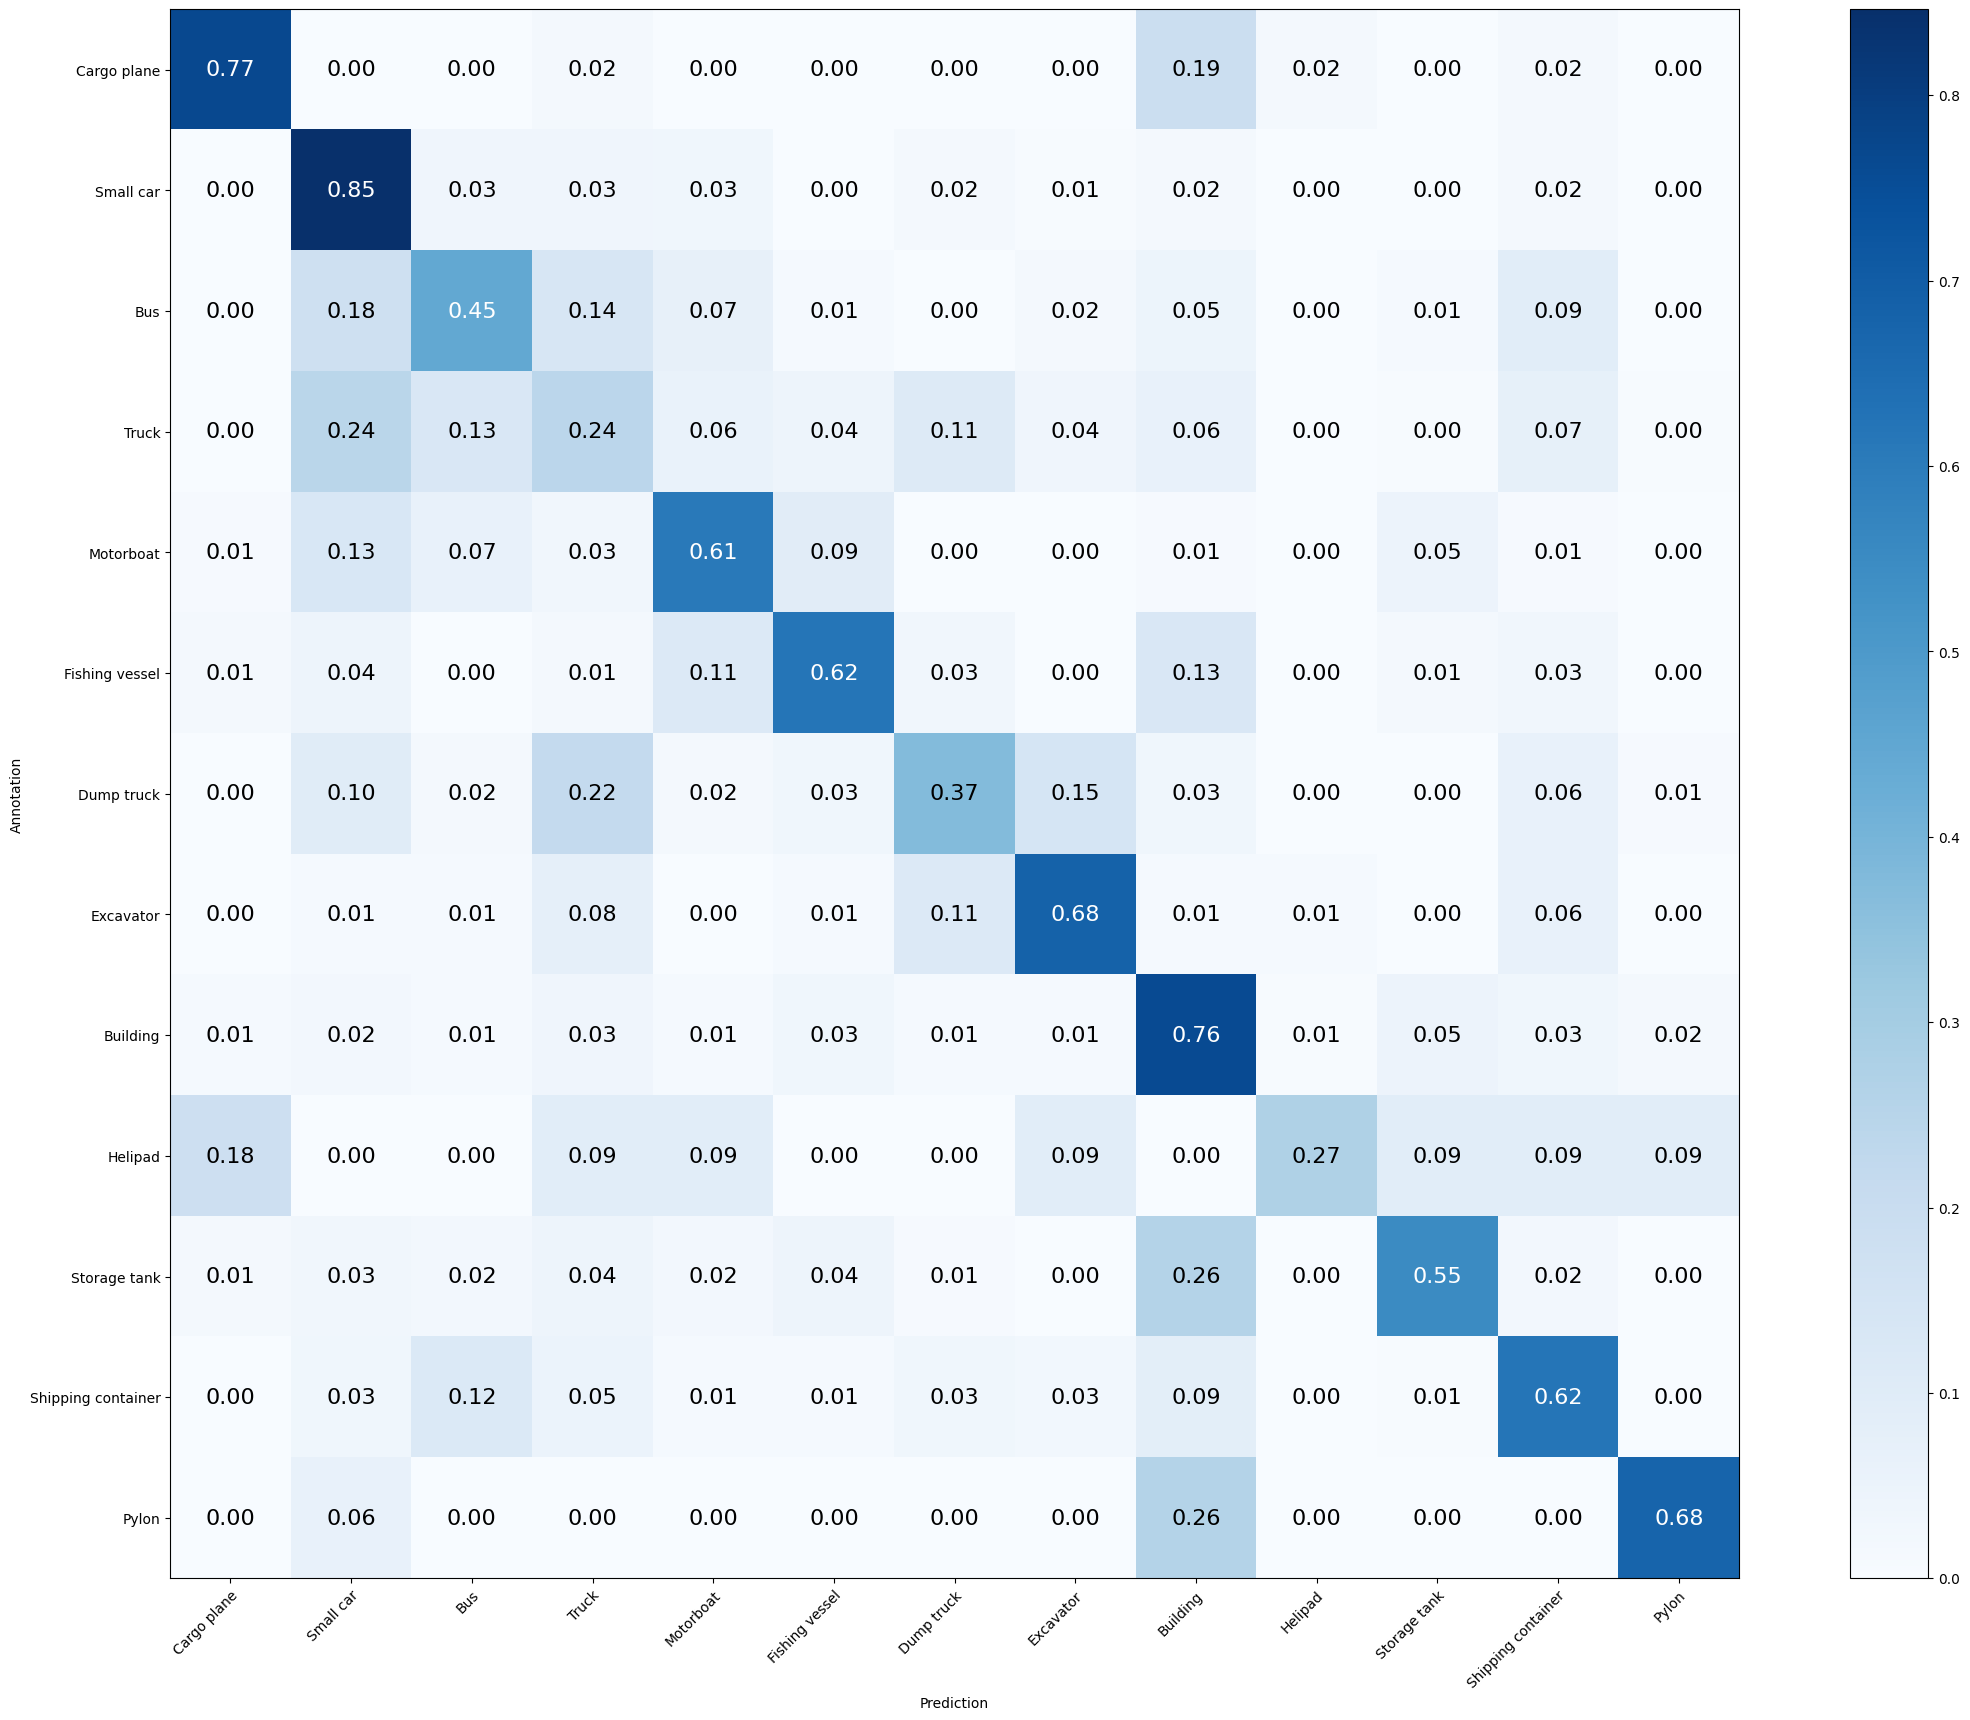

In [18]:
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(categories.values()))
draw_confusion_matrix(cm, categories, save_path=os.path.join(run_dir, 'confusion_matrix.png'))

In [19]:
import numpy as np

# Compute the accuracy
correct_samples_class = np.diag(cm).astype(float)
total_samples_class = np.sum(cm, axis=1).astype(float)
total_predicts_class = np.sum(cm, axis=0).astype(float)
print('Mean Accuracy: %.3f%%' % (np.sum(correct_samples_class) / np.sum(total_samples_class) * 100))
acc = correct_samples_class / np.maximum(total_samples_class, np.finfo(np.float64).eps)
print('Mean Recall: %.3f%%' % (acc.mean() * 100))
acc = correct_samples_class / np.maximum(total_predicts_class, np.finfo(np.float64).eps)
print('Mean Precision: %.3f%%' % (acc.mean() * 100))
for idx in range(len(categories)):
    # True/False Positives (TP/FP) refer to the number of predicted positives that were correct/incorrect.
    # True/False Negatives (TN/FN) refer to the number of predicted negatives that were correct/incorrect.
    tp = cm[idx, idx]
    fp = sum(cm[:, idx]) - tp
    fn = sum(cm[idx, :]) - tp
    tn = sum(np.delete(sum(cm) - cm[idx, :], idx))
    # True Positive Rate: proportion of real positive cases that were correctly predicted as positive.
    recall = tp / np.maximum(tp+fn, np.finfo(np.float64).eps)
    # Precision: proportion of predicted positive cases that were truly real positives.
    precision = tp / np.maximum(tp+fp, np.finfo(np.float64).eps)
    # True Negative Rate: proportion of real negative cases that were correctly predicted as negative.
    specificity = tn / np.maximum(tn+fp, np.finfo(np.float64).eps)
    # Dice coefficient refers to two times the intersection of two sets divided by the sum of their areas.
    # Dice = 2 |A∩B| / (|A|+|B|) = 2 TP / (2 TP + FP + FN)
    f1_score = 2 * ((precision * recall) / np.maximum(precision+recall, np.finfo(np.float64).eps))
    print('> %s: Recall: %.3f%% Precision: %.3f%% Specificity: %.3f%% Dice: %.3f%%' % (list(categories.values())[idx], recall*100, precision*100, specificity*100, f1_score*100))

Mean Accuracy: 60.907%
Mean Recall: 57.362%
Mean Precision: 58.535%
> Cargo plane: Recall: 76.562% Precision: 83.051% Specificity: 99.448% Dice: 79.675%
> Small car: Recall: 84.639% Precision: 67.711% Specificity: 91.316% Dice: 75.234%
> Bus: Recall: 44.633% Precision: 51.634% Specificity: 95.642% Dice: 47.879%
> Truck: Recall: 23.982% Precision: 34.641% Specificity: 93.954% Dice: 28.342%
> Motorboat: Recall: 60.748% Precision: 54.167% Specificity: 96.889% Dice: 57.269%
> Fishing vessel: Recall: 61.972% Precision: 49.438% Specificity: 97.506% Dice: 55.000%
> Dump truck: Recall: 37.097% Precision: 47.917% Specificity: 97.144% Dice: 41.818%
> Excavator: Recall: 68.354% Precision: 57.447% Specificity: 97.773% Dice: 62.428%
> Building: Recall: 75.766% Precision: 70.466% Specificity: 92.480% Dice: 73.020%
> Helipad: Recall: 27.273% Precision: 42.857% Specificity: 99.785% Dice: 33.333%
> Storage tank: Recall: 55.102% Precision: 74.312% Specificity: 98.380% Dice: 63.281%
> Shipping container:

In [20]:
import csv

# Save run results: config + confusion matrix in the run folder, one summary row in experiments/runs.csv
recall_class = correct_samples_class / np.maximum(total_samples_class, np.finfo(np.float64).eps)
precision_class = correct_samples_class / np.maximum(total_predicts_class, np.finfo(np.float64).eps)
np.savetxt(os.path.join(run_dir, 'confusion_matrix.csv'), cm, fmt='%d', delimiter=',', header=','.join(categories.values()))
with open(os.path.join(run_dir, 'config.json'), 'w', encoding='utf-8') as ofs:
    json.dump({'exp_id': EXP_ID, 'resolution': RES, 'batch_size': batch_size, 'epochs': epochs, 'optimizer': optimizer_config, 'loss': model.loss, 'monitor': 'val_mean_recall'}, ofs, indent=2, default=str)
summary = {
    'run_id': run_id,
    'exp_id': EXP_ID,
    'params': model.count_params(),
    'epochs_run': len(h.history['loss']),
    'best_epoch': best_idx + 1,
    'train_accuracy': round(float(h.history['accuracy'][best_idx]), 4),
    'val_accuracy': round(float(np.sum(correct_samples_class) / np.sum(total_samples_class)), 4),
    'val_mean_recall': round(float(recall_class.mean()), 4),
    'val_mean_precision': round(float(precision_class.mean()), 4),
    'val_min_recall': round(float(recall_class.min()), 4),
}
runs_file = os.path.join('experiments', 'runs.csv')
write_header = not os.path.exists(runs_file)
with open(runs_file, 'a', newline='', encoding='utf-8') as ofs:
    writer = csv.DictWriter(ofs, fieldnames=list(summary.keys()))
    if write_header:
        writer.writeheader()
    writer.writerow(summary)
print(summary)

{'run_id': 'EXP-010_20261003-160510', 'exp_id': 'EXP-010', 'params': 397581, 'epochs_run': 30, 'best_epoch': 20, 'train_accuracy': 0.6992, 'val_accuracy': 0.6091, 'val_mean_recall': 0.5736, 'val_mean_precision': 0.5854, 'val_min_recall': 0.2398}


#### Summary of the experiments
The final model comes from phases 0-5 of the sweep (one factor at a time; 3 seeds in the later decisions). Every run is in
`experiments/experiments.csv`, the figures and their interpretation in `hyperparameter_sweep.ipynb`, and the reasoning
with references in `LOGBOOK.md`. Validation mean recall (macro) after each phase:

In [21]:
import pandas as pd

# Validation results after each phase of delivery 1 (mean ± std over 3 seeds where available), from experiments/experiments.csv
progress = pd.DataFrame([
    ('0', 'baseline: raw pixels, linear model (EXP-001)', '0.282', '0.389'),
    ('1', 'Rescaling 1/255, callbacks monitoring mean recall (EXP-003)', '0.382', '0.413'),
    ('2', '16x16 input, Dense(256) (EXP-005)', '0.549', '0.600'),
    ('3', '4 hidden layers of 256 (EXP-006)', '0.572', '0.604'),
    ('4', 'LeakyReLU 0.3 (EXP-007, batch 16)', '0.587 ± 0.004', '0.626 ± 0.008'),
    ('5', 'final: Adam beta_1 0.95, batch 256, lr 1.2e-3 (EXP-010)', '0.578 ± 0.007', '0.616 ± 0.006')
], columns=['phase', 'change kept', 'val mean recall', 'val accuracy'])
progress.style.hide(axis='index')

phase,change kept,val mean recall,val accuracy
0,"baseline: raw pixels, linear model (EXP-001)",0.282,0.389
1,"Rescaling 1/255, callbacks monitoring mean recall (EXP-003)",0.382,0.413
2,"16x16 input, Dense(256) (EXP-005)",0.549,0.600
3,4 hidden layers of 256 (EXP-006),0.572,0.604
4,"LeakyReLU 0.3 (EXP-007, batch 16)",0.587 ± 0.004,0.626 ± 0.008
5,"final: Adam beta_1 0.95, batch 256, lr 1.2e-3 (EXP-010)",0.578 ± 0.007,0.616 ± 0.006


#### Testing
Try to improve the results provided in the competition.

In [22]:
import os
import numpy as np

anns = []
for (dirpath, dirnames, filenames) in os.walk('./xview_recognition/xview_test'):
    for filename in sorted(filenames):
        if not filename.lower().endswith('.tif'):  # skip non-image files, e.g. Windows ':Zone.Identifier' copies (ISS-006)
            continue
        image = GenericImage(dirpath + '/' + filename)
        image.tile = np.array([0, 0, 224, 224])
        obj = GenericObject()
        obj.bb = (0, 0, 224, 224)
        obj.category = dirpath[dirpath.rfind('/')+1:]
        image.add_object(obj)
        anns.append(image)
print('Number of testing images: ' + str(len(anns)))

Number of testing images: 2365


In [23]:
import numpy as np
from xview_data import load_cache, list_test_files

model.load_weights('model.keras')
# Same preprocessing as in training: images cached at the same resolution, Rescaling inside the model
x_test = load_cache('test', RES)
test_index = {f: i for i, f in enumerate(list_test_files())}
probs_test = predict_probs(model, x_test, np.arange(len(x_test)))
predictions_data = {"images": {}, "annotations": {}}
for idx, ann in enumerate(anns):
    image_data = {"image_id": ann.filename.split('/')[-1], "filename": ann.filename, "width": int(ann.tile[2]), "height": int(ann.tile[3])}
    predictions_data["images"][idx] = image_data
    predictions = probs_test[test_index[ann.filename.split('/')[-1]]]
    for obj_pred in ann.objects:
        # Save prediction
        pred_category = list(categories.values())[np.argmax(predictions)]
        pred_score = np.max(predictions)
        annotation_data = {"image_id": ann.filename.split('/')[-1], "category_id": pred_category, "bbox": [int(x) for x in obj_pred.bb]}
        predictions_data["annotations"][idx] = annotation_data

In [24]:
with open("prediction.json", "w") as outfile:
    json.dump(predictions_data, outfile)